In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp10: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
np.random.seed(10); tf.random.set_seed(10)
X,y=make_classification(n_samples=600,n_features=10,n_informative=6,n_redundant=2,random_state=10)
Xa,Xt,ya,yt=train_test_split(X,y,test_size=.2,random_state=10,stratify=y)
sc=StandardScaler(); Xa=sc.fit_transform(Xa); Xt=sc.transform(Xt)
def build(l2=0,drop=0):
    return tf.keras.Sequential([tf.keras.layers.Input((10,)),tf.keras.layers.Dense(128,activation="relu",kernel_regularizer=tf.keras.regularizers.l2(l2)),tf.keras.layers.Dropout(drop),tf.keras.layers.Dense(64,activation="relu",kernel_regularizer=tf.keras.regularizers.l2(l2)),tf.keras.layers.Dense(1,activation="sigmoid")])
rows=[]; histories={}
configs=[("Baseline",0,0,False),("L2 0.001",.001,0,False),("L2 0.01",.01,0,False),("L2 0.1",.1,0,False),("Dropout .2",0,.2,False),("Dropout .3",0,.3,False),("Dropout .5",0,.5,False),("Early stopping",0,.3,True)]
for name,l2,d,early in configs:
    m=build(l2,d); m.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
    cb=[tf.keras.callbacks.EarlyStopping(patience=8,restore_best_weights=True)] if early else []
    h=m.fit(Xa,ya,validation_split=.2,epochs=80,batch_size=32,verbose=0,callbacks=cb)
    tr=m.evaluate(Xa,ya,verbose=0)[1]; te=m.evaluate(Xt,yt,verbose=0)[1]
    rows.append([name,len(h.history["loss"]),round(tr,4),round(te,4),round(tr-te,4)])
    histories[name]=h.history
result=pd.DataFrame(rows,columns=["Model","Epochs","Train accuracy","Test accuracy","Train-test gap"])
print(result.to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(histories["Baseline"]["loss"],label="Train"); ax[0].plot(histories["Baseline"]["val_loss"],label="Validation"); ax[0].set_title("Baseline loss"); ax[0].legend()
ax[1].bar(result["Model"],result["Test accuracy"]); ax[1].tick_params(axis="x",rotation=70); ax[1].set_title("Test accuracy by regularisation")
plt.tight_layout(); plt.show()

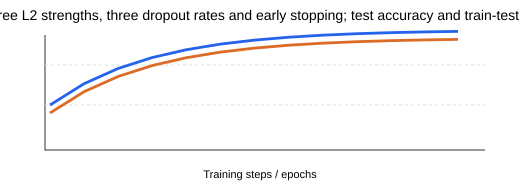

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.